# Reference-use patterns

Figure 2 and Figures S3–S5. Run cells in order; figures are displayed inline.


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from pathlib import Path
from types import SimpleNamespace
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as show_inline

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'analysis' / '_config.py').exists())
SOURCE = ROOT / 'data'
plt.rcParams.update({'pdf.fonttype': 42, 'svg.fonttype': 'none'})

import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

read = pd.read_csv


## Shared display functions

In [2]:
"""Manuscript terminology for figure display text; data identifiers stay fixed."""
from pathlib import Path
EXPORT_CALLBACK = None
R_GROUPS = ['Persistently resistant', 'Consistently non-resistant']
ALPHA_GROUPS = ['Mean α < 0.10 in both periods', 'Mean α ≥ 0.10 in both periods']
TEXT = {'Persistent resistance': R_GROUPS[0], 'Stable non-resistance': R_GROUPS[1], 'Delayed adoption': 'Later non-resistant', 'Personal academic background': 'Individual characteristics', 'Personal background': 'Individual characteristics', 'Personal\nbackground': 'Individual\ncharacteristics', 'External environment': 'Environmental characteristics', 'External\nenvironment': 'Environmental\ncharacteristics', 'Early relative resistance R': 'Early resistance (R)', 'Late relative resistance R': 'Late resistance (R)', 'Early mean R': 'Early resistance (R)', 'Late mean R': 'Late resistance (R)', 'Incremental out-of-sample R²\n(percentage points)': 'Additional predictive R²\n(percentage points)', 'Coefficient on later resistance R': 'Adjusted difference in\nsubsequent resistance (R)', 'Remaining resistant authors (%)': 'Authors remaining\ncontinuously resistant (%)', 'Early resistant authors retained (%)': 'Initially resistant authors remaining\ncontinuously resistant (%)', 'Previously cited references (%)': 'Reference reuse (%)', 'Previously cited references': 'Reference reuse', 'Reference subfield variety': 'Reference variety', 'Reference subfield balance': 'Reference balance', 'Reference subfield diversity': 'Reference diversity', 'Subfield variety': 'Reference variety', 'Subfield balance': 'Reference balance', 'Subfield diversity': 'Reference diversity', 'Corresponding\ncollaborators': 'Corresponding-author\ncollaborators', 'Corresponding collaborators': 'Corresponding-author collaborators', 'Early mean α': 'Early mean AI-associated\nwriting score (α)', 'Late mean α': 'Late mean AI-associated\nwriting score (α)', 'α (GPT-3.5 reference)': 'AI-associated writing score (α)\nGPT-3.5 reference', 'α (Qwen2.5 reference)': 'AI-associated writing score (α)\nQwen2.5 reference', 'Paper-level threshold': 'AI-assistance classification cutoff', 'Late period': 'Period', 'Both years': '2025 and 2026', 'Mean α <0.10 in both periods': ALPHA_GROUPS[0], 'Mean α ≥0.10 in both periods': ALPHA_GROUPS[1], 'Mean α <0.10\nin both periods': 'Mean α < 0.10\nin both periods', 'Mean α ≥0.10\nin both periods': 'Mean α ≥ 0.10\nin both periods', 'Authors remaining below α threshold (%)': 'Remaining authors with\nmean α < 0.10 (%)', 'Initial knowledge base': 'References cited in first five years', 'Pre-2023 knowledge base': 'References cited before 2023', 'Subsequent knowledge reused': 'Other previously cited references', 'Subsequently reused references': 'Other previously cited references', 'First-observed references': 'First observed references', 'Initial five-year library\nFixed-library references': 'First five years\nPreviously cited references', 'Initial five-year library\nSubsequently reused references': 'First five years\nOther previously cited references', 'Initial five-year library\nFirst-observed references': 'First five years\nFirst observed references', 'Pre-2023 library\nFixed-library references': 'Before 2023\nPreviously cited references', 'Pre-2023 library\nSubsequently reused references': 'Before 2023\nOther previously cited references', 'Pre-2023 library\nFirst-observed references': 'Before 2023\nFirst observed references', 'Mean R in first five\npublications': 'Mean resistance in first five\npublications (R)', 'Mean R in last five\npublications': 'Mean resistance in last five\npublications (R)', 'Positive R in final block (%)': 'Authors with positive\nlast-block resistance (%)', 'Affiliation-country setting': 'Institutional country category', 'Adjusted R difference\n(non-English − English)': 'Adjusted resistance difference (R)\n(non-English − English)', 'Adjusted difference in later\nnon-resistance (percentage points)': 'Adjusted difference in subsequent\nnon-resistance probability (percentage points)'}

def display(text, filename):
    stem = Path(str(filename)).stem
    if stem == 'FigureS3_field_prevalence_retention_2y_2y' and text == 'Remaining resistant authors (%)':
        return 'Initially resistant authors (%)'
    if stem == 'FigureS_absolute_alpha_predictors_collaborators' and text == 'Adjusted probability difference\n(percentage points)':
        return 'Adjusted probability difference\n(mean α < 0.10; percentage points)'
    if stem == 'FigureS6_binary_threshold_persistence_curves' and text.startswith('α ≥ '):
        return text.replace('α ≥ ', 'α cutoff = ')
    if 'absolute_alpha' in stem and text in ['Persistent resistance', 'Stable non-resistance']:
        return ALPHA_GROUPS[['Persistent resistance', 'Stable non-resistance'].index(text)]
    return TEXT.get(text, text)

def harmonize(figure, filename):
    """Update labels and legends while preserving every plotted observation."""
    changes = []
    for index, axis in enumerate(figure.axes):
        for which in ['x', 'y']:
            ticks = axis.get_xticklabels() if which == 'x' else axis.get_yticklabels()
            old = [t.get_text() for t in ticks]
            new = [display(t, filename) for t in old]
            if old != new:
                limits = axis.get_xlim() if which == 'x' else axis.get_ylim()
                positions = axis.get_xticks() if which == 'x' else axis.get_yticks()
                if which == 'x':
                    axis.set_xticks(positions, new)
                    axis.set_xlim(limits)
                else:
                    axis.set_yticks(positions, new)
                    axis.set_ylim(limits)
                changes.extend((dict(axis=index, role=which + ' tick', old=a, new=b) for a, b in zip(old, new) if a != b))
        for role, artist in [('x label', axis.xaxis.label), ('y label', axis.yaxis.label), ('title', axis.title)]:
            old = artist.get_text()
            new = display(old, filename)
            if new != old:
                artist.set_text(new)
                changes.append(dict(axis=index, role=role, old=old, new=new))
        for artist in axis.texts:
            old = artist.get_text()
            new = display(old, filename)
            if new != old:
                artist.set_text(new)
                changes.append(dict(axis=index, role='annotation', old=old, new=new))
    legends = list(figure.legends) + [ax.get_legend() for ax in figure.axes if ax.get_legend() is not None]
    for legend in legends:
        for artist in [legend.get_title(), *legend.get_texts()]:
            old = artist.get_text()
            new = display(old, filename)
            if old != new:
                artist.set_text(new)
                changes.append(dict(axis='legend', role='legend', old=old, new=new))
    stem = Path(str(filename)).stem
    if stem == 'Figure2_reference_profiles':
        figure.axes[1].get_legend().set_bbox_to_anchor((-0.06, 1.0))
    if stem == 'FigureS_absolute_alpha_predictors_collaborators':
        figure.axes[1].set_xlim(-0.48, 1.48)
    if stem == 'FigureS_delayed_reference_reuse':
        figure.legends[0].set_bbox_to_anchor((0.5, 0.98))
    return changes

"""Shared numerical labels for the grouped predictive-contribution figures."""

def contribution_labels(axis, rows, positions, color, fontsize=11):
    for row, position in zip(rows.itertuples(), positions):
        personal = row.Index == 'Personal academic background'
        boundary = row.upper if personal else row.lower
        axis.annotate(f'{row.incremental_R2 * 100:.3f}', (boundary * 100, position), xytext=(9 if personal else -9, 0), textcoords='offset points', ha='left' if personal else 'right', va='center', fontsize=fontsize, color=color)

def show_figure(fig, name, scale=False):
    """Display the manuscript figure in the notebook."""
    if scale:
        for axis in fig.axes:
            for text in [axis.xaxis.label, axis.yaxis.label, axis.title,
                         *axis.get_xticklabels(), *axis.get_yticklabels(), *axis.texts]:
                text.set_fontsize(text.get_fontsize() * 1.5)
            axis.tick_params(pad=9)
            axis.xaxis.labelpad = axis.yaxis.labelpad = 18
    harmonize(fig, name)
    fig.canvas.draw()
    show_inline(fig)
    plt.close(fig)

export = show_figure
pub = SimpleNamespace(MAIN_ORANGE='#DD9B26', MAIN_BLUE='#67A9CC', ROUTES={})
def save(fig, name):
    show_figure(fig, pub.ROUTES[name], scale=True)
pub.save = save


from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib.path import Path as PlotPath
from matplotlib.patches import PathPatch, Rectangle

def ribbon(ax, x0, x1, lo0, hi0, lo1, hi1, color, alpha):
    assert abs(hi0 - lo0 - (hi1 - lo1)) < 1e-12
    control = 0.48 * (x1 - x0)
    vertices = [(x0, lo0), (x0 + control, lo0), (x1 - control, lo1), (x1, lo1), (x1, hi1), (x1 - control, hi1), (x0 + control, hi0), (x0, hi0), (x0, lo0)]
    codes = [PlotPath.MOVETO, PlotPath.CURVE4, PlotPath.CURVE4, PlotPath.CURVE4, PlotPath.LINETO, PlotPath.CURVE4, PlotPath.CURVE4, PlotPath.CURVE4, PlotPath.CLOSEPOLY]
    ax.add_patch(PathPatch(PlotPath(vertices, codes), facecolor=color, edgecolor='none', alpha=alpha, zorder=1))

def _river_from_summaries(state_file, flow_file, absolute=False):
    source = ROOT / 'data'
    states = pd.read_csv(source / state_file, dtype={'period': str}).set_index('period').loc[['early', '2025', '2026']]
    flows = pd.read_csv(source / flow_file, dtype={'period_from': str, 'period_to': str})
    total = int(states.iloc[0]['cohort_authors' if absolute else 'authors'])
    positive = states['n' if absolute else 'resistant_authors'].to_numpy(int)
    counts = []
    for first, second in [('early', '2025'), ('2025', '2026')]:
        current = flows[flows.period_from.eq(first) & flows.period_to.eq(second)]
        matrix = np.zeros((2, 2), int)
        for row in current.itertuples():
            a = int(row.state_from == ('mean α < 0.10' if absolute else 'Resistant'))
            b = int(row.state_to == ('mean α < 0.10' if absolute else 'Resistant'))
            matrix[a, b] = row.authors
        counts.append(matrix)
    for j, matrix in enumerate(counts):
        np.testing.assert_array_equal(matrix.sum(axis=1), [total - positive[j], positive[j]])
        np.testing.assert_array_equal(matrix.sum(axis=0), [total - positive[j + 1], positive[j + 1]])
    return dict(authors=total, stages=['early', '2025', '2026'], positive=positive, probabilities=positive / total, counts=counts)

def river_data():
    return _river_from_summaries('resistance_states.csv', 'resistance_flows.csv')

def absolute_alpha_river_data():
    return _river_from_summaries('absolute_alpha_states.csv', 'absolute_alpha_flows.csv', absolute=True)

def draw_resistance_river(ax, data=None, fontsize=12, state_labels=None):
    data = river_data() if data is None else data
    state_labels = ('Resistant', 'Non-\nresistant') if state_labels is None else state_labels
    p = data['probabilities']
    total = data['authors']
    orange = '#DD9B26'
    purple = '#BDA1DB'
    green = '#79C494'
    grey = '#BBC2C9'
    pale = '#D8DDE2'
    width = 0.42
    gap = 0.065
    top = 1 + gap
    for j, matrix in enumerate(data['counts']):
        rr = matrix[1, 1] / total
        rn = matrix[1, 0] / total
        nr = matrix[0, 1] / total
        x0 = j + width / 2
        x1 = j + 1 - width / 2
        ribbon(ax, x0, x1, p[j] + gap + nr, top, p[j + 1] + gap + rn, top, pale, 0.82)
        ribbon(ax, x0, x1, 0, rr, 0, rr, orange, 0.62)
        ribbon(ax, x0, x1, rr, p[j], p[j + 1] + gap, p[j + 1] + gap + rn, purple, 0.66)
        ribbon(ax, x0, x1, p[j] + gap, p[j] + gap + nr, rr, p[j + 1], green, 0.7)
    for j, stage in enumerate(['Early\n2023–2024', '2025', '2026']):
        for resistant, bottom, height, color in [(True, 0, p[j], orange), (False, p[j] + gap, 1 - p[j], grey)]:
            ax.add_patch(Rectangle((j - width / 2, bottom), width, height, facecolor=color, edgecolor='none', zorder=5))
            center = bottom + height / 2
            label = state_labels[0 if resistant else 1]
            multiline = '\n' in label
            ax.text(j, center + (0.065 if multiline else 0.045), label, ha='center', va='center', fontsize=fontsize * 0.87, color='#26303A', linespacing=1.05, zorder=6)
            ax.text(j, center - (0.065 if multiline else 0.055), f'{height * 100:.1f}%', ha='center', va='center', fontsize=fontsize * 1.12, fontweight='bold', color='#26303A', zorder=6)
        ax.text(j, -0.085, stage, ha='center', va='top', fontsize=fontsize * 1.12, color='#26303A')
    ax.set(xlim=(-0.31, 2.31), ylim=(-0.015, 1.11))
    ax.set_axis_off()
    return data

## Figure 2. Reference use in the two stable resistance groups


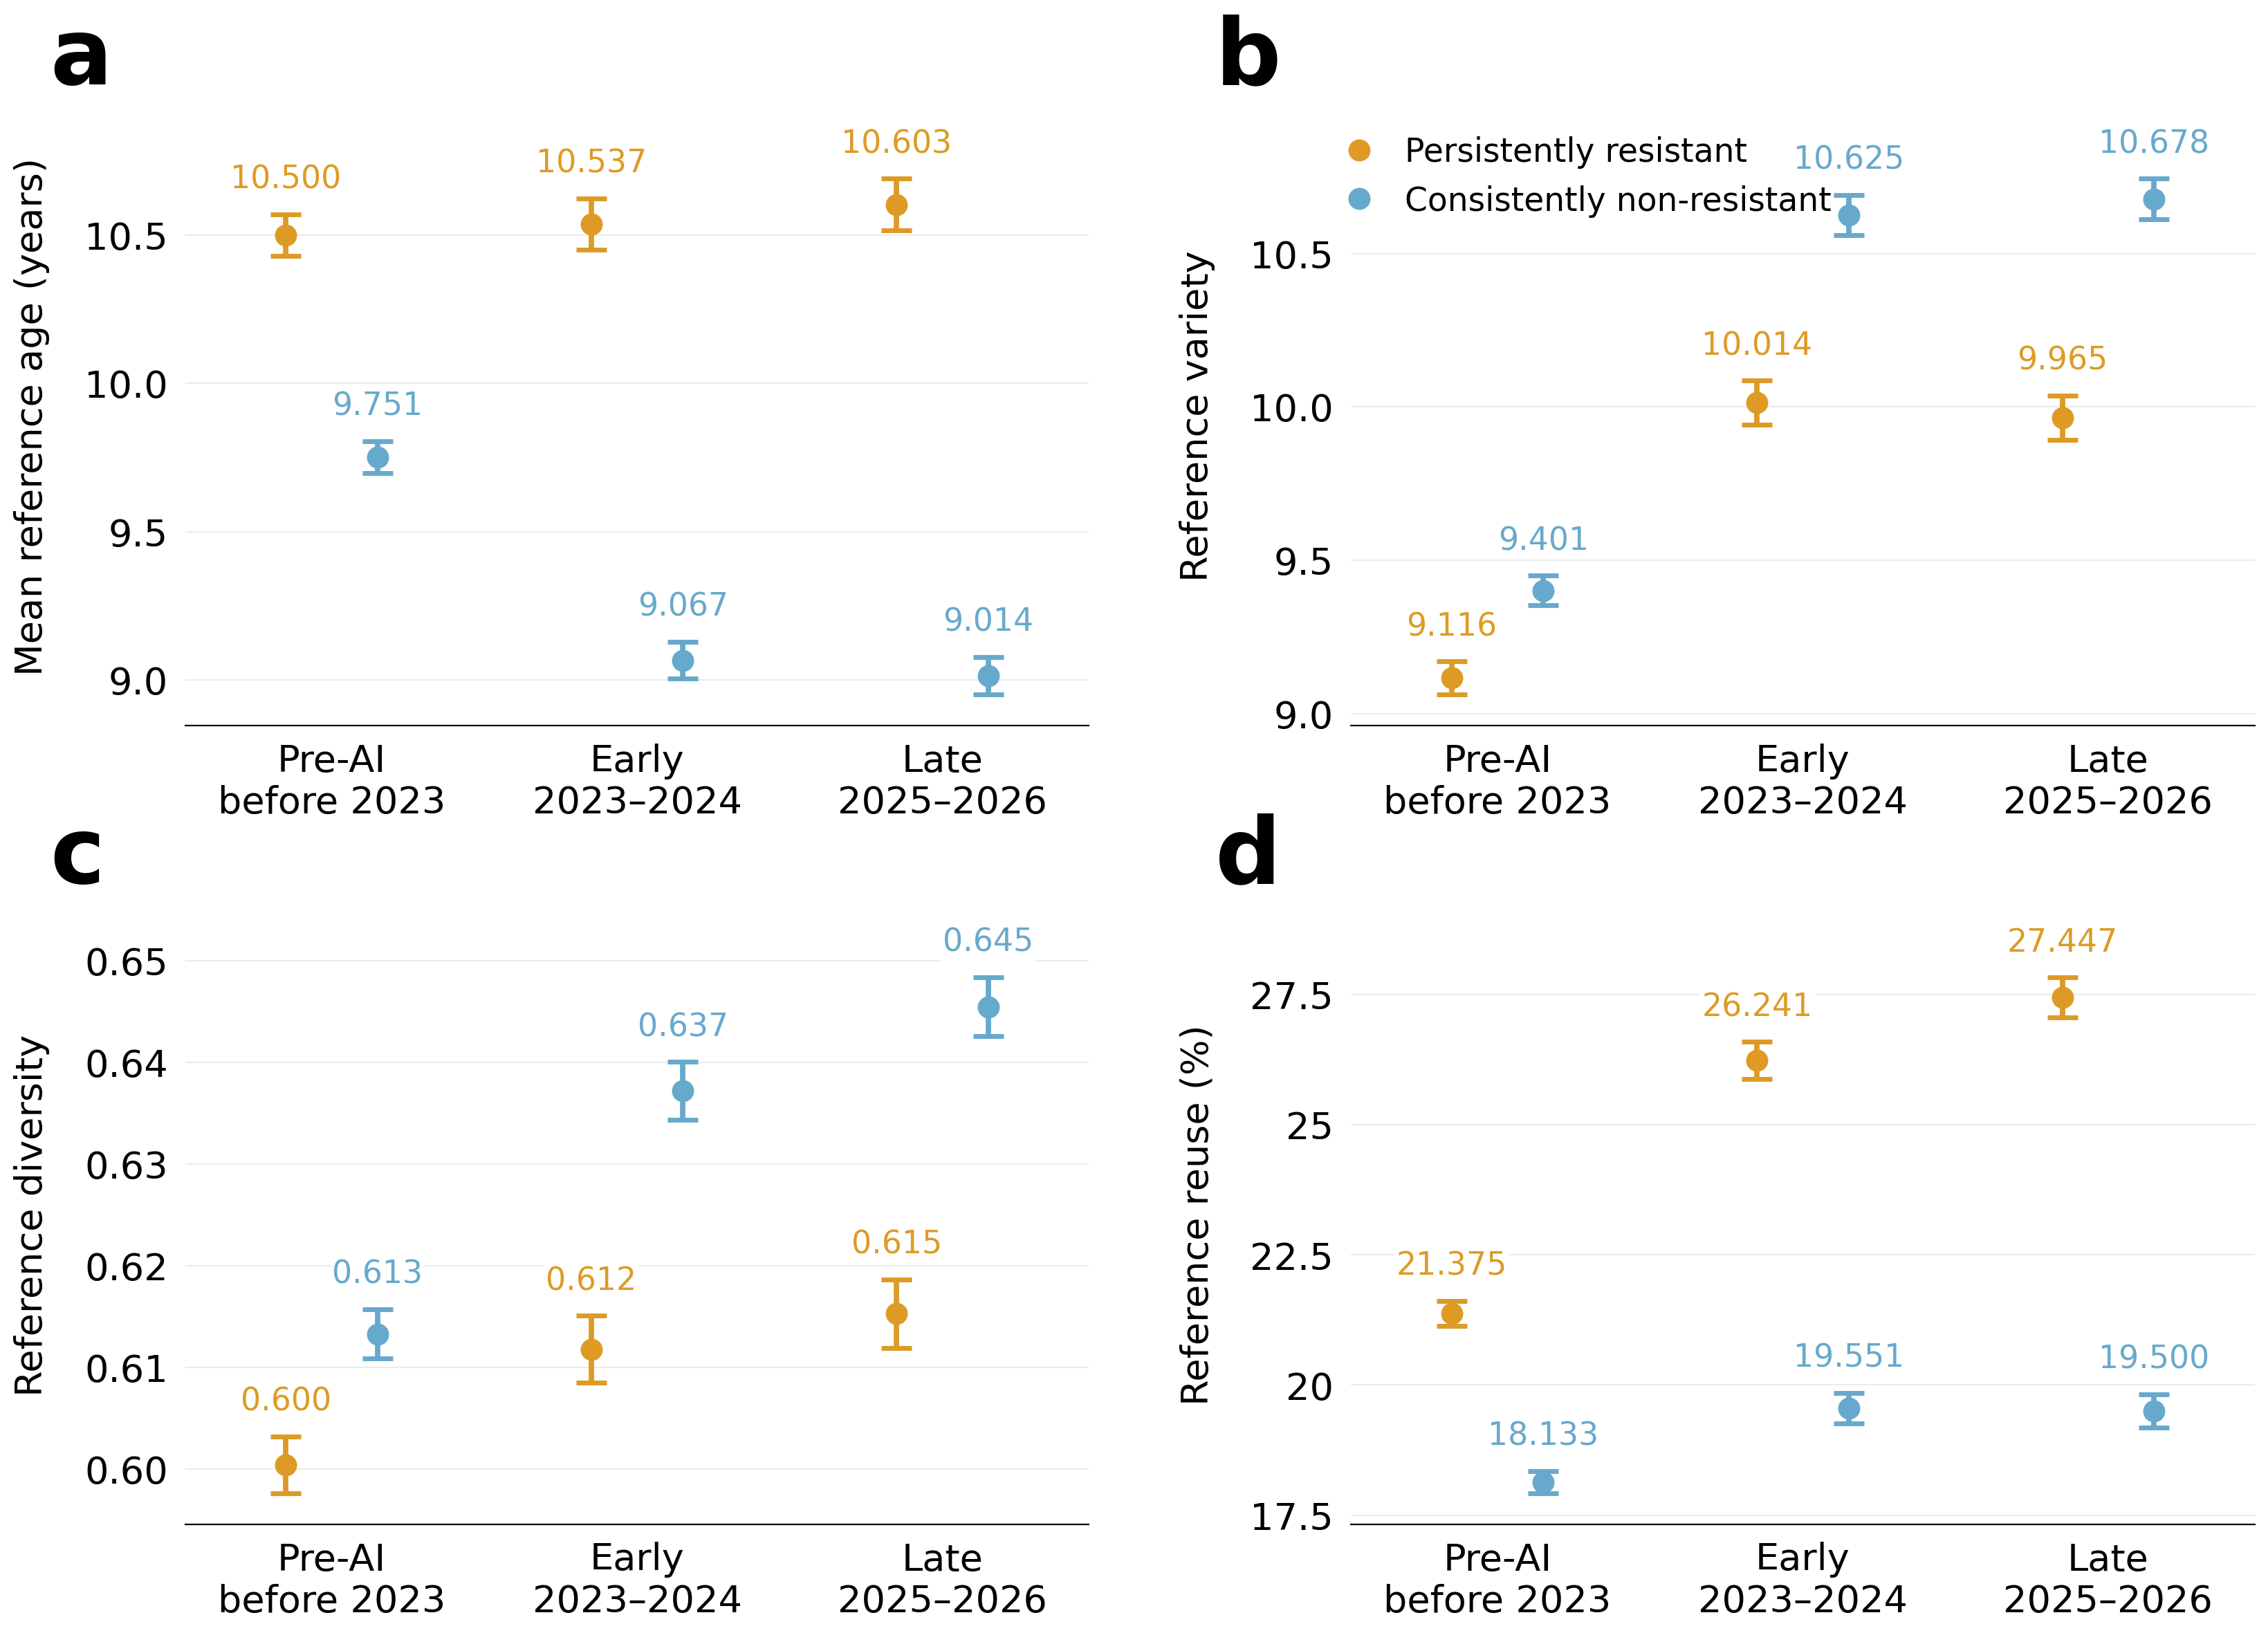

In [3]:
from pathlib import Path
from types import SimpleNamespace
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, FormatStrFormatter, FixedLocator, FuncFormatter
YEAR_COLORS = {2025: '#BDA1DB', 2026: '#79C494'}
publication = pub

def figure2():
    means = pd.read_csv(SOURCE / 'reference_profiles/adjusted_three_period_means.csv')
    panels = [('age_mean', 'Mean reference age (years)', 0.5, '%.1f'), ('variety', 'Reference variety', 0.5, '%.1f'), ('diversity', 'Reference diversity', 0.01, '%.2f'), ('reuse', 'Previously cited references (%)', 2.5, '%g')]
    plt.rcParams.update({'font.family': 'Arial', 'font.size': 13, 'pdf.fonttype': 42})
    figure, axes = plt.subplots(2, 2, figsize=(17, 12.5))
    figure.subplots_adjust(left=0.105, right=0.985, bottom=0.105, top=0.925, wspace=0.29, hspace=0.29)
    for panel_index, (axis, (metric, ylabel, step, pattern)) in enumerate(zip(axes.flat, panels)):
        panel = means[means.metric.eq(metric)]
        for group, color, offset in [(1, publication.MAIN_ORANGE, -0.15), (0, publication.MAIN_BLUE, 0.15)]:
            values = panel[panel.resistant.eq(group)].set_index('period').loc[['Historical', 'Early', 'Late']]
            positions = np.arange(3) + offset
            axis.errorbar(positions, values['mean'], yerr=[values['mean'] - values.lower, values.upper - values['mean']], fmt='o', linestyle='none', color=color, markersize=10.5, elinewidth=2.8, capsize=8, capthick=2.5)
            for position, value, upper in zip(positions, values['mean'], values.upper):
                axis.annotate(f'{value:.3f}', (position, upper), xytext=(0, 10), textcoords='offset points', ha='center', va='bottom', fontsize=11, color=color)
        span = panel.upper.max() - panel.lower.min()
        lower = panel.lower.min() - 0.06 * span
        upper = panel.upper.max() + 0.14 * span
        ticks = np.arange(np.ceil(lower / step) * step, upper - step * 1e-06, step)
        while len(ticks) < 4:
            lower = np.ceil(lower / step) * step - step * 1.02
            ticks = np.arange(np.ceil(lower / step) * step, upper - step * 1e-06, step)
        assert len(ticks) >= 4
        axis.set_ylim(lower, upper)
        axis.set_xlim(-0.48, 2.48)
        axis.yaxis.set_major_locator(FixedLocator(ticks))
        axis.yaxis.set_major_formatter(FuncFormatter(lambda value, position, fmt=pattern: fmt % value))
        axis.set_xticks(range(3), ['Pre-AI\nbefore 2023', 'Early\n2023–2024', 'Late\n2025–2026'])
        axis.set_ylabel(ylabel)
        axis.spines[['left', 'top', 'right']].set_visible(False)
        axis.tick_params(axis='both', which='both', length=0)
        axis.text(-0.15, 1.005, chr(ord('a') + panel_index), transform=axis.transAxes, fontsize=32, fontweight='bold', ha='left', va='bottom')
        sizes = [text.get_fontsize() for text in axis.texts]
        for text, size in zip(axis.texts, sizes):
            text.set_fontsize(size * 1.5)
        figure.canvas.draw()
        boxes = [text.get_window_extent(figure.canvas.get_renderer()).expanded(1.05, 1.2) for text in axis.texts]
        for text, size in zip(axis.texts, sizes):
            text.set_fontsize(size)
        for tick in ticks:
            height = axis.transData.transform((0, tick))[1]
            excluded = [(max(-0.48, axis.transData.inverted().transform((box.x0, height))[0]), min(2.48, axis.transData.inverted().transform((box.x1, height))[0])) for box in boxes if box.y0 <= height <= box.y1]
            start = -0.48
            for left, right in sorted(excluded):
                if right <= start:
                    continue
                if left > start:
                    axis.plot([start, left], [tick, tick], color='#E5E5E5', linewidth=0.75, alpha=0.75, zorder=0)
                start = max(start, right)
            if start < 2.48:
                axis.plot([start, 2.48], [tick, tick], color='#E5E5E5', linewidth=0.75, alpha=0.75, zorder=0)
    handles = [Line2D([], [], color=color, marker='o', linestyle='none', markersize=10.5, label=label) for color, label in [(publication.MAIN_ORANGE, 'Persistent resistance'), (publication.MAIN_BLUE, 'Stable non-resistance')]]
    axes[0, 1].legend(handles=handles, loc='upper left', frameon=False, fontsize=17, handletextpad=0.4, borderaxespad=0.5)
    publication.ROUTES['Figure2_reference_profiles'] = Path('main/Figure2_reference_profiles.png')
    publication.save(figure, 'Figure2_reference_profiles')

figure2()

## Figure S3. Reference use across three resistance groups

Panels: mean reference age, median reference age, variety, balance, diversity and reuse.


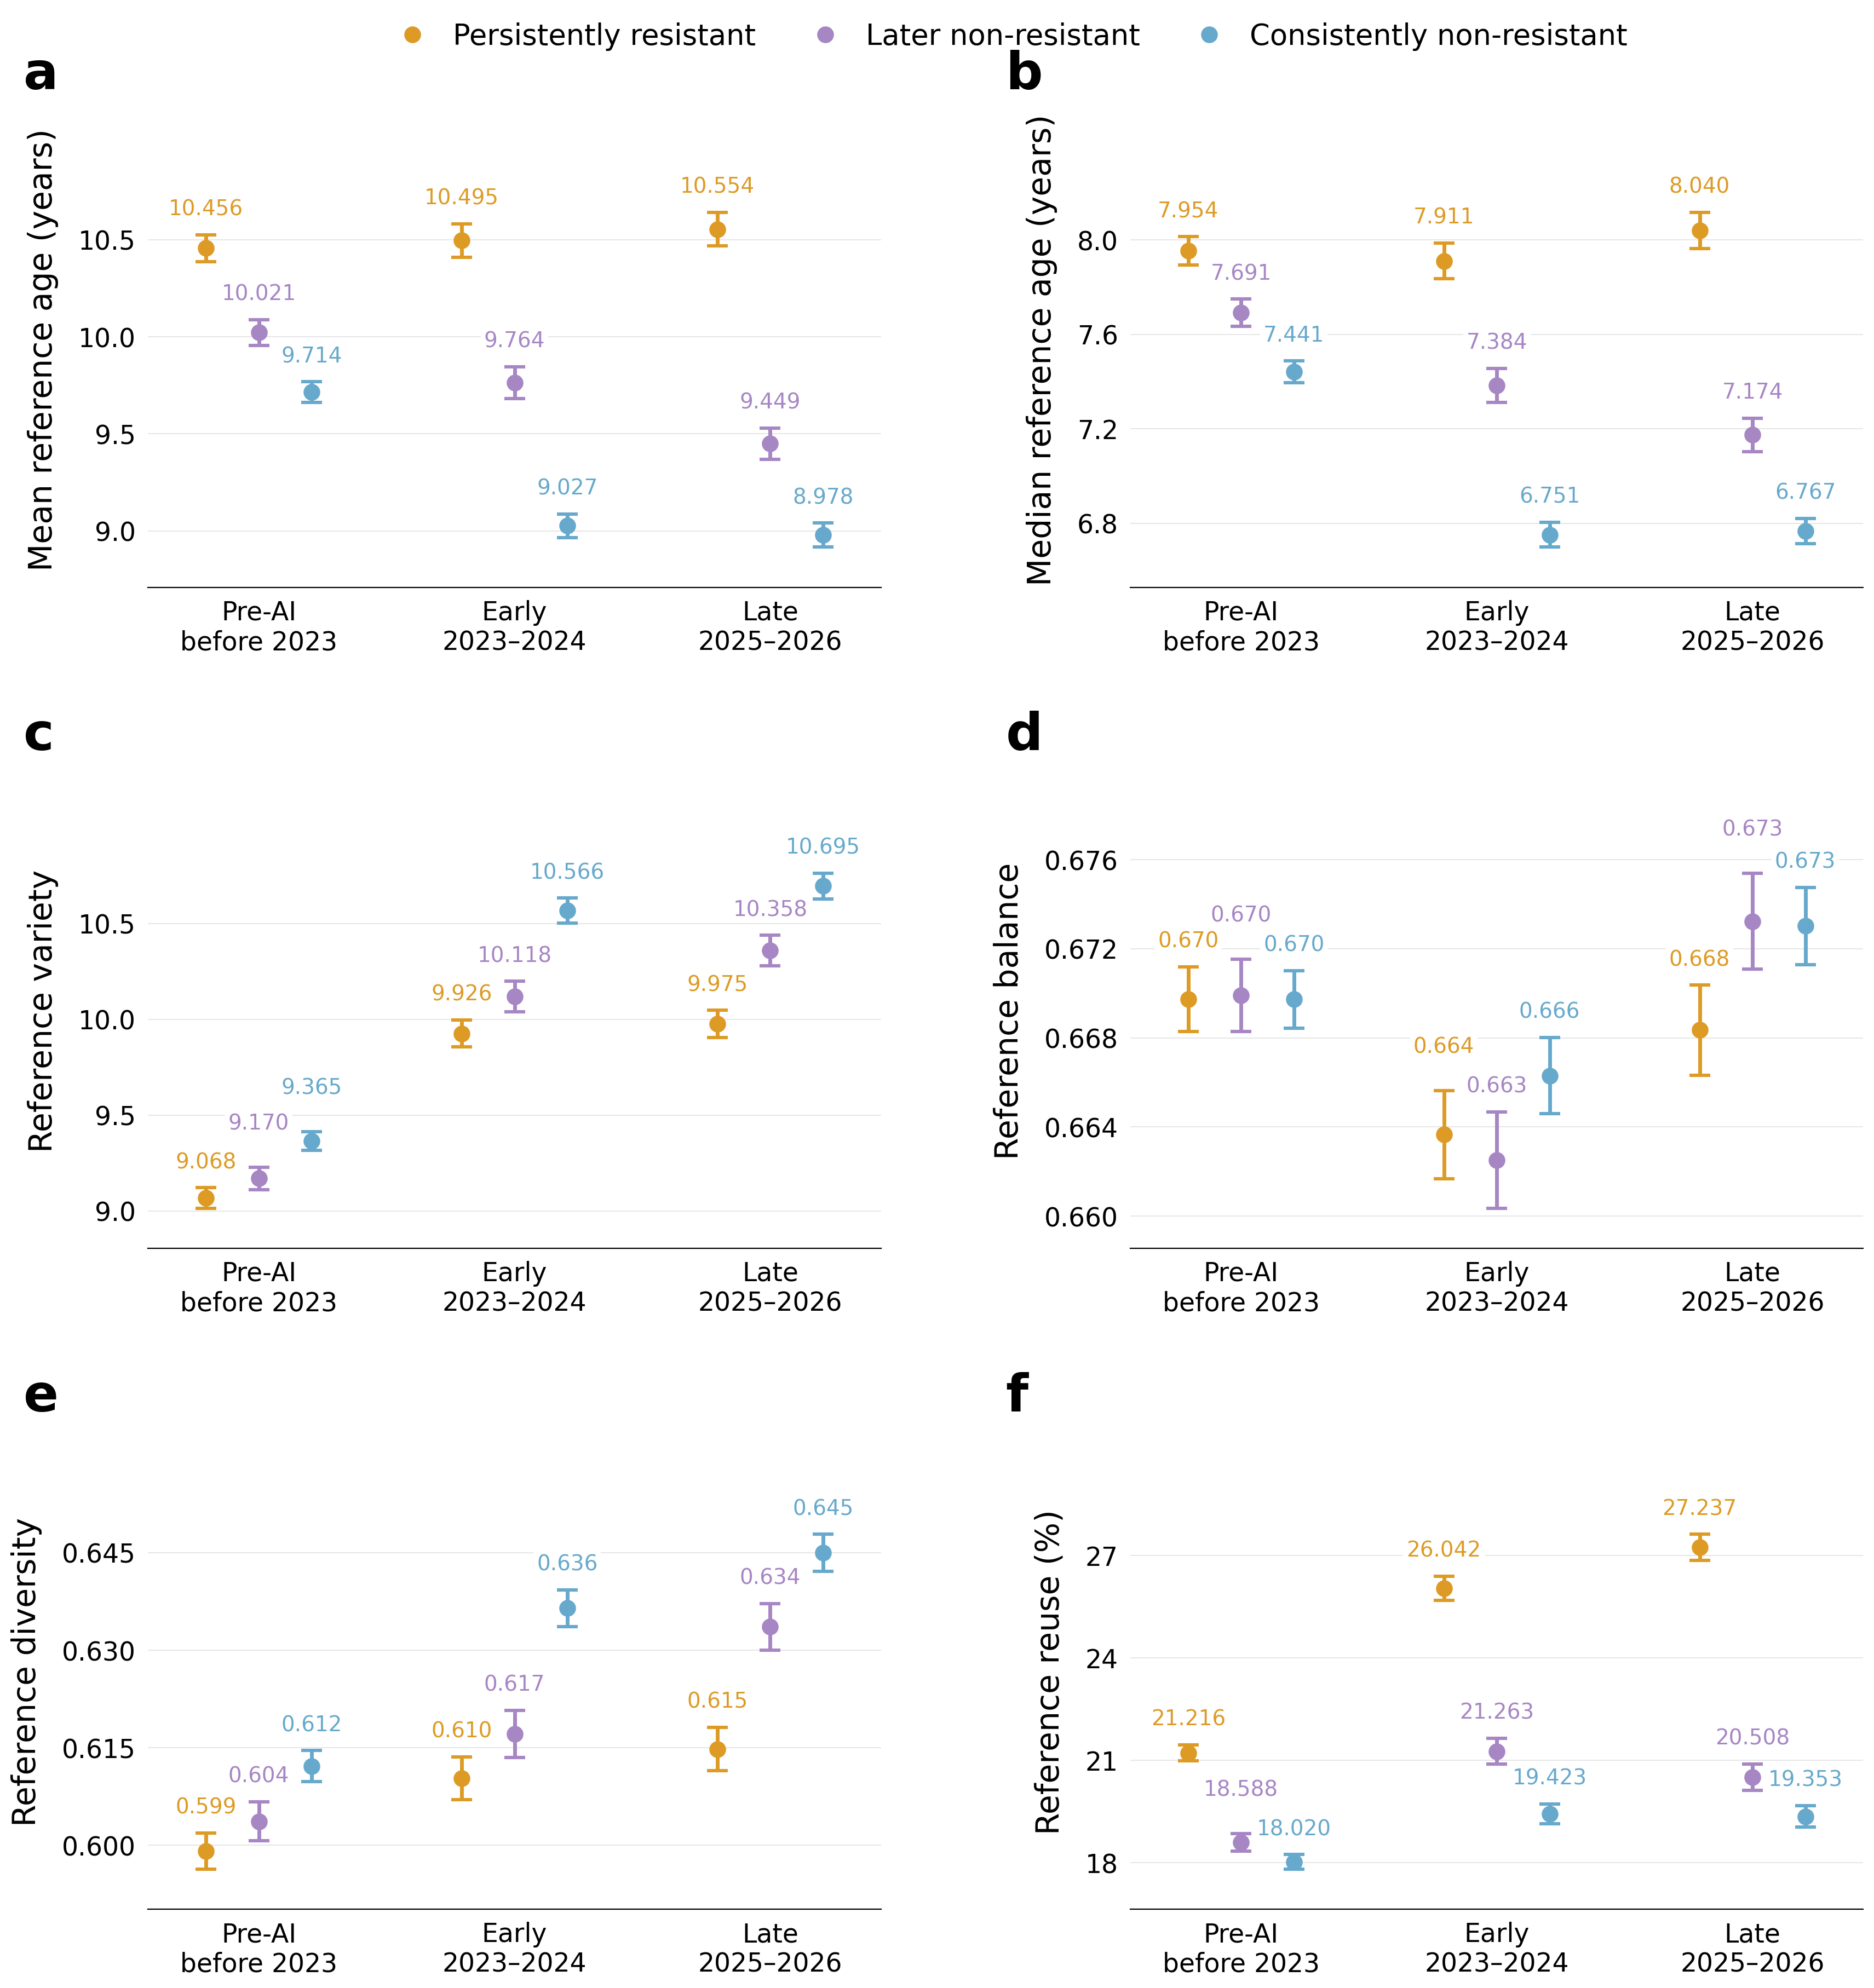

In [4]:
from pathlib import Path
from types import SimpleNamespace
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, FormatStrFormatter, FixedLocator, FuncFormatter
GROUPS = ['Persistent resistance', 'Delayed adoption', 'Stable non-resistance']
NAMES = ['Persistently resistant', 'Later non-resistant', 'Consistently non-resistant']
COLORS = ['#DD9B26', '#A786C4', '#67A9CC']
YEARS = {2025: '#BDA1DB', 2026: '#79C494'}
PERIODS = ['Historical', 'Early', 'Late']
X_LABELS = {'Historical': 'Pre-AI\nbefore 2023', 'Early': 'Early\n2023–2024', 'Late': 'Late\n2025–2026'}

def panel_letter(ax, letter):
    ax.text(-0.17, 1.025, letter, transform=ax.transAxes, ha='left', va='bottom', fontsize=34, fontweight='bold')

def clean(ax):
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(length=0, pad=8, labelsize=17)
    ax.set_axisbelow(True)

def stagger(ax, texts):
    fig = ax.figure
    fig.canvas.draw()
    placed = []
    for text in sorted(texts, key=lambda t: t.get_window_extent(fig.canvas.get_renderer()).y0):
        for _ in range(20):
            box = text.get_window_extent(fig.canvas.get_renderer()).expanded(1.035, 1.12)
            if not any((box.overlaps(other) for other in placed)):
                break
            dx, dy = text.get_position()
            text.set_position((dx, dy + 12))
            fig.canvas.draw()
        placed.append(text.get_window_extent(fig.canvas.get_renderer()).expanded(1.035, 1.12))

def grid(ax):
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    boxes = [t.get_window_extent(renderer).expanded(1.12, 1.3) for t in ax.texts if t.get_transform() != ax.transAxes]
    left, right = ax.get_xlim()
    for tick in ax.get_yticks():
        if not ax.get_ylim()[0] < tick < ax.get_ylim()[1]:
            continue
        y = ax.transData.transform((0, tick))[1]
        gaps = []
        for box in boxes:
            if box.y0 <= y <= box.y1:
                gaps.append((max(left, ax.transData.inverted().transform((box.x0, y))[0]), min(right, ax.transData.inverted().transform((box.x1, y))[0])))
        position = left
        for start, end in sorted(gaps) + [(right, right)]:
            if start > position:
                ax.plot([position, start], [tick, tick], color='#E6E6E6', linewidth=0.7, zorder=0)
            position = max(position, end)

def references_panel(ax, frame, periods, ylabel, letter, title='', offsets=(-0.31, 0, 0.31)):
    assert len(frame) == len(periods) * 3
    assert np.isfinite(frame[['mean', 'lower', 'upper']]).all().all()
    texts = []
    x = np.arange(len(periods)) * 1.5
    for group, color, offset in zip(GROUPS, COLORS, offsets):
        local = frame[frame.group.eq(group)].set_index('period').loc[periods]
        ax.errorbar(x + offset, local['mean'], yerr=[local['mean'] - local.lower, local.upper - local['mean']], fmt='o', linestyle='none', color=color, markersize=10, elinewidth=2.5, capsize=7, capthick=2.2)
        for pos, value, upper in zip(x + offset, local['mean'], local.upper):
            texts.append(ax.annotate(f'{value:.3f}', (pos, upper), xytext=(0, 10), textcoords='offset points', ha='center', va='bottom', fontsize=14, color=color))
    lo, hi = (frame.lower.min(), frame.upper.max())
    span = max(hi - lo, 0.001)
    low = lo - 0.12 * span
    high = hi + 0.3 * span
    ax.set_ylim(low, high)
    ax.set_xlim(-0.65, x[-1] + 0.65)
    for nbins in [5, 6, 7, 8]:
        ticks = MaxNLocator(nbins=nbins, min_n_ticks=5).tick_values(low, high)
        ticks = ticks[(ticks > low) & (ticks < hi + 0.12 * span)]
        if len(ticks) >= 4:
            break
    assert len(ticks) >= 4
    ax.set_yticks(ticks)
    ax.set_xticks(x, [X_LABELS[p] for p in periods])
    ax.set_ylabel(ylabel, fontsize=21, labelpad=13)
    if title:
        ax.set_title(title, fontsize=22, pad=18)
    clean(ax)
    panel_letter(ax, letter)
    stagger(ax, texts)
    grid(ax)

def group_legend(fig, y=0.985):
    handles = [Line2D([], [], marker='o', linestyle='none', color=c, markersize=10, label=n) for c, n in zip(COLORS, NAMES)]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.55, y), ncol=3, fontsize=19, frameon=False, columnspacing=1.4, handletextpad=0.4)

def three_group_references():
    means = read(SOURCE / 'trajectories/reference_adjusted_means.csv')
    metrics = ['age_mean', 'age_median', 'variety', 'balance', 'diversity', 'reuse']
    frame = means[means.section.eq('Core reference measures') & means.metric.isin(metrics)]
    assert len(frame) == 54
    fig, axes = plt.subplots(3, 2, figsize=(18, 19.2))
    fig.subplots_adjust(left=0.115, right=0.985, bottom=0.075, top=0.93, wspace=0.34, hspace=0.39)
    labels = ['Mean reference age (years)', 'Median reference age (years)', 'Reference variety', 'Reference balance', 'Reference diversity', 'Reference reuse (%)']
    for letter, ax, metric, label in zip('abcdef', axes.flat, metrics, labels):
        references_panel(ax, frame[frame.metric.eq(metric)], PERIODS, label, letter)
    group_legend(fig)
    export(fig, 'FigureS3_three_group_reference_profiles')

def fixed_libraries():
    means = read(SOURCE / 'trajectories/reference_adjusted_means.csv')
    fig, axes = plt.subplots(1, 2, figsize=(18, 7.3))
    fig.subplots_adjust(left=0.105, right=0.985, bottom=0.19, top=0.8, wspace=0.34)
    records = []
    for letter, ax, section, title in zip('ab', axes, ['Initial five-year library', 'Pre-2023 library'], ['First five years', 'Before 2023']):
        frame = means[means.section.eq(section) & means.metric.eq('fixed_library')]
        assert len(frame) == 6
        references_panel(ax, frame, ['Early', 'Late'], 'References (%)', letter, title)
        records.append(frame)
    group_legend(fig, y=0.99)
    export(fig, 'FigureS5_three_group_fixed_libraries')

plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Arial','Helvetica','DejaVu Sans'],'font.size':18,'pdf.fonttype':42,'svg.fonttype':'none','legend.frameon':False,'axes.spines.top':False,'axes.spines.right':False,'axes.spines.left':False,'axes.linewidth':.8})
three_group_references()

## Figure S4. Reference age composition across three resistance groups

Panels show references aged 0–7, 8–19 and at least 20 years. Points and intervals use the existing three-group adjusted estimates.


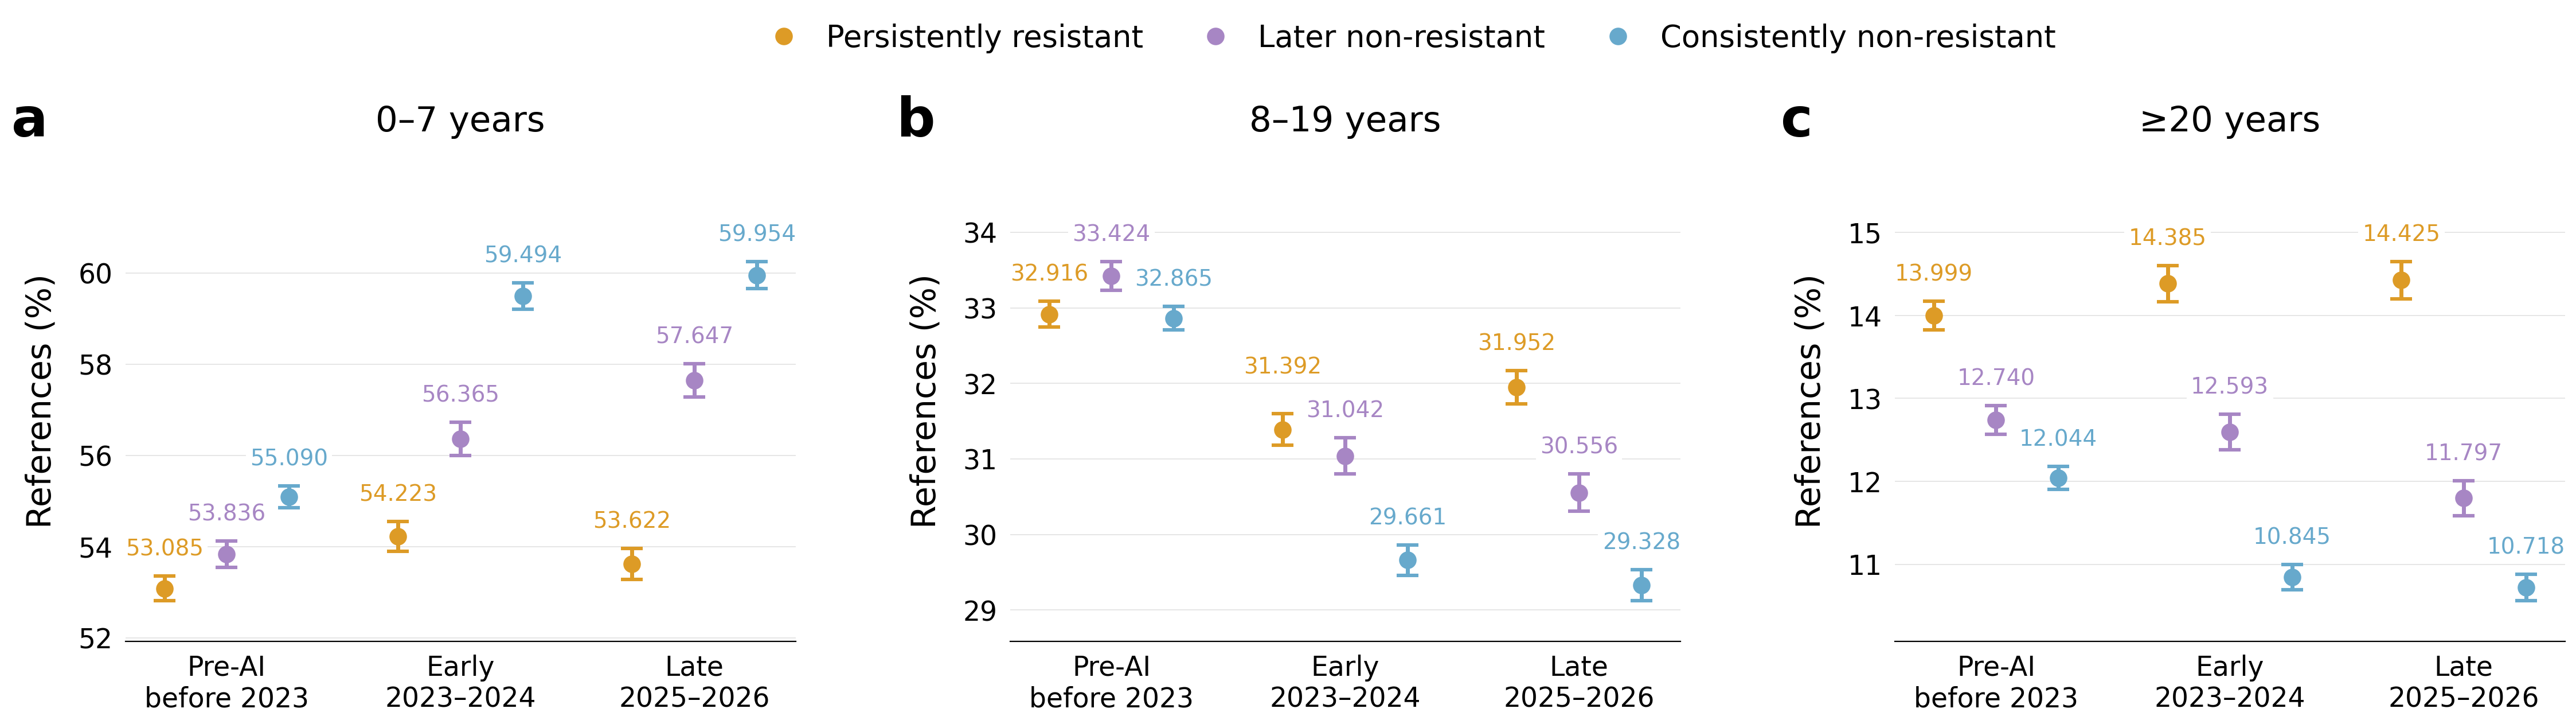

In [5]:
def three_group_age_composition():
    means = read(SOURCE / 'trajectories/reference_adjusted_means.csv')
    bands = ['age_0_7', 'age_8_19', 'age_20_plus']
    frame = means[means.section.eq('Reference age bands') & means.metric.isin(bands)]
    assert len(frame) == 27
    assert not frame.duplicated(['metric', 'period', 'group']).any()
    assert set(frame.group) == set(GROUPS)
    assert frame[['mean', 'lower', 'upper']].ge(0).all().all()
    assert frame[['mean', 'lower', 'upper']].le(100).all().all()
    fig, axes = plt.subplots(1, 3, figsize=(23, 7.5))
    fig.subplots_adjust(left=0.065, right=0.99, bottom=0.24, top=0.80, wspace=0.32)
    for letter, ax, band, title in zip('abc', axes, bands, ['0–7 years', '8–19 years', '≥20 years']):
        references_panel(ax, frame[frame.metric.eq(band)], PERIODS, 'References (%)', letter, title, offsets=(-0.40, 0, 0.40))
    group_legend(fig, y=0.99)
    export(fig, 'FigureS4_three_group_reference_age_composition')

three_group_age_composition()


## Figure S5. Fixed reference libraries across three resistance groups

Panels show the shares belonging to the initial five-year and pre-2023 reference libraries.


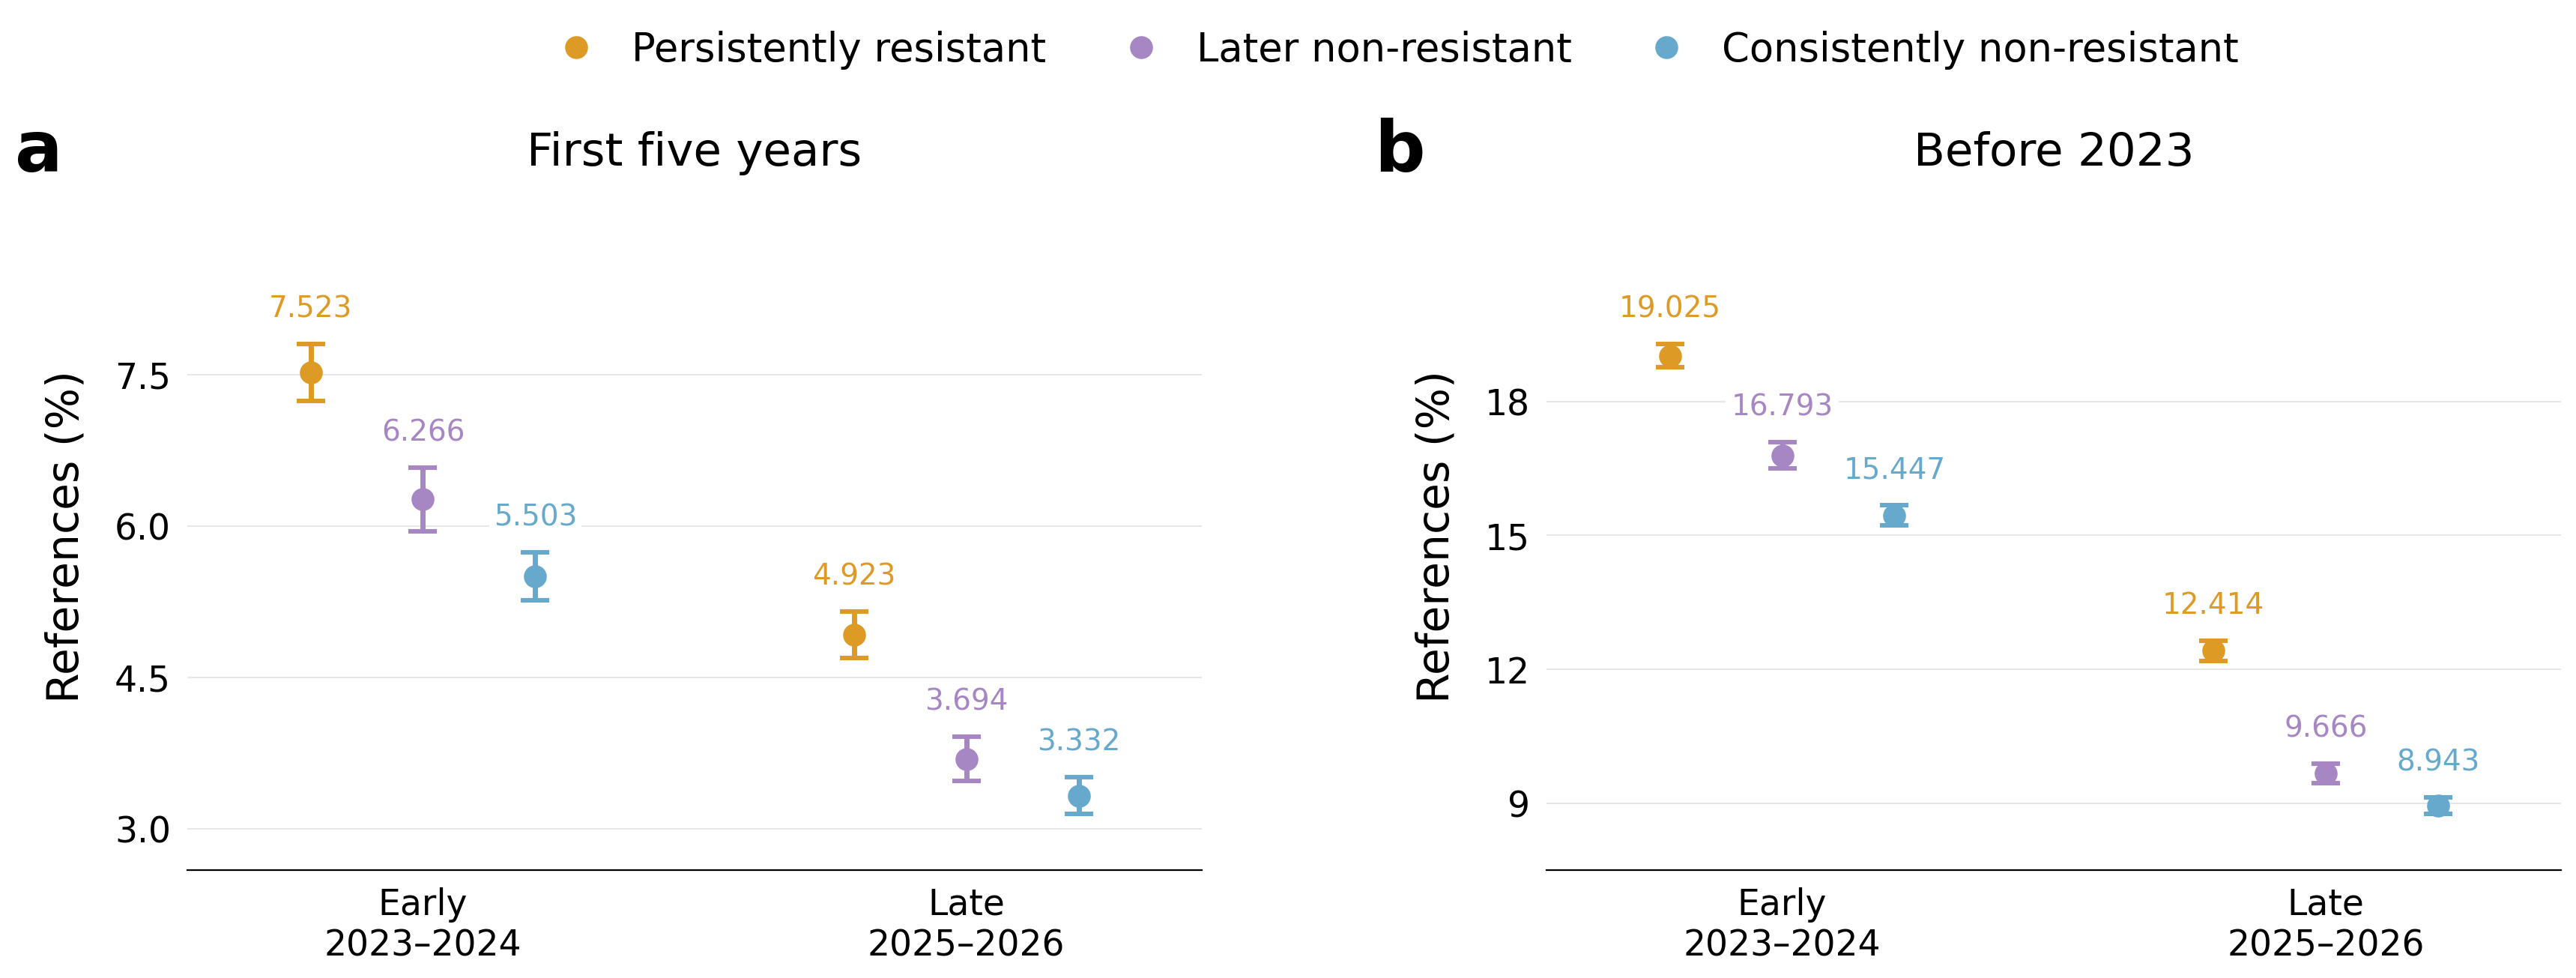

In [6]:
fixed_libraries()